# BoW, TF-IDF, Word2Vec e BERT

notebook para centralizar e comparar os modelos

`pip install pandas numpy scikit-learn gensim sentence-transformers matplotlib`

In [2]:
import ast
import numpy as np
import pandas as pd

from gensim.models import Word2Vec
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt

In [3]:
def carregar_dados(caminho='gutenberg_books.csv', coluna_texto='text_final'):
    df = pd.read_csv(caminho, dtype={'book_id': str})
    df['texto'] = df[coluna_texto].fillna('')
    return df

df = carregar_dados()
print('Livros carregados:', len(df))
print(
    df[['book_id', 'title']]
    .assign(texto=df['texto'].str[:100])
    .head(2)
    .to_string(index=False)
)

Livros carregados: 312
book_id                    title                                                                                                texto
   1342      Pride and Prejudice pride prejudice jane austen novel published 1813 follows elizabeth bennet must learn see past first 
   2701 Moby Dick; Or, The Whale moby dick whale herman melville epic novel published 1851 sailor ishmael narrates obsessive quest ca


In [4]:
def buscar_por_matriz(modelo, matriz, consulta, df, top_n=5):
    consulta_vec = modelo.transform([consulta])
    similaridades = cosine_similarity(consulta_vec, matriz).ravel()
    indices = similaridades.argsort()[::-1][:top_n]

    resultado = df.iloc[indices].copy()
    resultado['similaridade'] = similaridades[indices]
    return resultado[['book_id', 'title', 'similaridade']]

bow_vectorizer = CountVectorizer()
X_bow = bow_vectorizer.fit_transform(df['texto'])

tfidf_vectorizer = TfidfVectorizer()
X_tfidf = tfidf_vectorizer.fit_transform(df['texto'])

print('BoW shape:', X_bow.shape)
print('TF-IDF shape:', X_tfidf.shape)

BoW shape: (312, 7212)
TF-IDF shape: (312, 7212)


In [5]:
def embedding_livro(tokens, modelo):
    vetores = [modelo.wv[token] for token in tokens if token in modelo.wv]
    if not vetores:
        return np.zeros(modelo.vector_size)
    return np.mean(vetores, axis=0)

def buscar_por_embedding(embeddings, consulta, df, top_n=5):
    tokens = consulta.lower().split()
    vetores = [model_w2v.wv[token] for token in tokens if token in model_w2v.wv]
    if not vetores:
        return pd.DataFrame(columns=['book_id', 'title', 'similaridade'])

    consulta_emb = np.mean(vetores, axis=0).reshape(1, -1)
    similaridades = cosine_similarity(consulta_emb, embeddings).ravel()
    indices = similaridades.argsort()[::-1][:top_n]

    resultado = df.iloc[indices].copy()
    resultado['similaridade'] = similaridades[indices]
    return resultado[['book_id', 'title', 'similaridade']]

df['tokens_w2v'] = df['texto'].str.split()

model_w2v = Word2Vec(
    sentences=df['tokens_w2v'].tolist(),
    vector_size=100,
    window=5,
    min_count=2,
    workers=1,
    sg=1,
    epochs=20
)

embeddings_w2v = np.array([embedding_livro(tokens, model_w2v) for tokens in df['tokens_w2v']])
print('Word2Vec embeddings shape:', embeddings_w2v.shape)
print('Tamanho do vocabulário:', len(model_w2v.wv))

Word2Vec embeddings shape: (312, 100)
Tamanho do vocabulário: 3541


In [6]:
bert_model = SentenceTransformer('all-MiniLM-L6-v2')

embeddings_bert = bert_model.encode(
    df['texto'].tolist(),
    show_progress_bar=False
)

print('BERT embeddings shape:', embeddings_bert.shape)

def buscar_por_bert(consulta, df, top_n=5):
    consulta_emb = bert_model.encode([consulta])
    similaridades = cosine_similarity(consulta_emb, embeddings_bert).ravel()
    indices = similaridades.argsort()[::-1][:top_n]

    resultado = df.iloc[indices].copy()
    resultado['similaridade'] = similaridades[indices]
    return resultado[['book_id', 'title', 'similaridade']]

d:\Marcelli\Facul\PLN\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Usuario\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
d:\Marcelli\Facul\PLN\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `hu

BERT embeddings shape: (312, 384)


busca e recomendação simples

In [19]:
def comparar_modelos(consulta, top_n=5):
    comparacao = {
        'BoW': buscar_por_matriz(bow_vectorizer, X_bow, consulta, df, top_n),
        'TF-IDF': buscar_por_matriz(tfidf_vectorizer, X_tfidf, consulta, df, top_n),
        'Word2Vec': buscar_por_embedding(embeddings_w2v, consulta, df, top_n),
        'BERT': buscar_por_bert(consulta, df, top_n)
    }
    return comparacao

consulta = 'science space exploration physics'
resultados = comparar_modelos(consulta, top_n=5)

for nome, tabela in resultados.items():
    print(f'\n--- {nome} ---')
    display(tabela.rename(columns={
        'book_id': 'ID do livro',
        'title': 'T\u00edtulo',
        'similaridade': 'Similaridade',
    }))


--- BoW ---


,ID do livro,Título,Similaridade
76,50290,Space Station 1,0.212598
269,76352,The world below,0.163299
147,48893,"Mademoiselle de Maupin, Volume 1 (of 2)",0.089622
219,83,"From the Earth to the moon; and, round the moon",0.077152
168,18857,A Journey to the Centre of the Earth,0.076472



--- TF-IDF ---


,ID do livro,Título,Similaridade
76,50290,Space Station 1,0.267040
269,76352,The world below,0.118329
219,83,"From the Earth to the moon; and, round the moon",0.098502
168,18857,A Journey to the Centre of the Earth,0.069310
148,19742,The Heather-Moon,0.064108



--- Word2Vec ---


,ID do livro,Título,Similaridade
75,57669,The problem of Cell 13,0.969511
300,44833,"Chaucer's Works, Volume 2 — Boethius and Troilus",0.968694
276,77099,"The magic ring, Vol. 3 (of 3)",0.964635
282,51252,The Book of the Thousand Nights and a Night — ...,0.961569
308,9473,"The Knights of the Cross, or, Krzyzacy: Histor...",0.959692



--- BERT ---


,ID do livro,Título,Similaridade
219,83,"From the Earth to the moon; and, round the moon",0.334791
168,18857,A Journey to the Centre of the Earth,0.294658
76,50290,Space Station 1,0.275026
251,3526,"Five Weeks in a Balloon Or, Journeys and Disco...",0.241110
269,76352,The world below,0.239494


trocar a variável `consulta` por frases como:

- `religion morality`
- `love romance`
- `adventure war`
- `science fiction future`

### Clusterização, PCA e visualização


In [8]:
N_CLUSTERS = 4

representacoes = {
    'BoW': X_bow,
    'TF-IDF': X_tfidf,
    'Word2Vec': embeddings_w2v,
    'BERT': embeddings_bert
}

resultados_clusterizacao = {}

for nome, matriz in representacoes.items():
    kmeans = KMeans(
        n_clusters=N_CLUSTERS,
        random_state=42,
        n_init=10
    )
    clusters = kmeans.fit_predict(matriz)

    matriz_pca = matriz.toarray() if hasattr(matriz, 'toarray') else np.asarray(matriz)
    coordenadas = PCA(n_components=2).fit_transform(matriz_pca)
    score = silhouette_score(matriz, clusters)

    resultados_clusterizacao[nome] = {
        'clusters': clusters,
        'coordenadas_pca': coordenadas,
        'silhouette': score
    }

    print(f'\n=== {nome} ===')
    print(f'Silhouette: {score:.4f}')
    print(pd.Series(clusters, name='cluster').value_counts().sort_index())


=== BoW ===
Silhouette: 0.0621
cluster
0      6
1    174
2    131
3      1
Name: count, dtype: int64

=== TF-IDF ===
Silhouette: 0.0018
cluster
0    92
1    67
2    99
3    54
Name: count, dtype: int64

=== Word2Vec ===
Silhouette: 0.2127
cluster
0    91
1    64
2    76
3    81
Name: count, dtype: int64

=== BERT ===
Silhouette: 0.0356
cluster
0     72
1     58
2    127
3     55
Name: count, dtype: int64


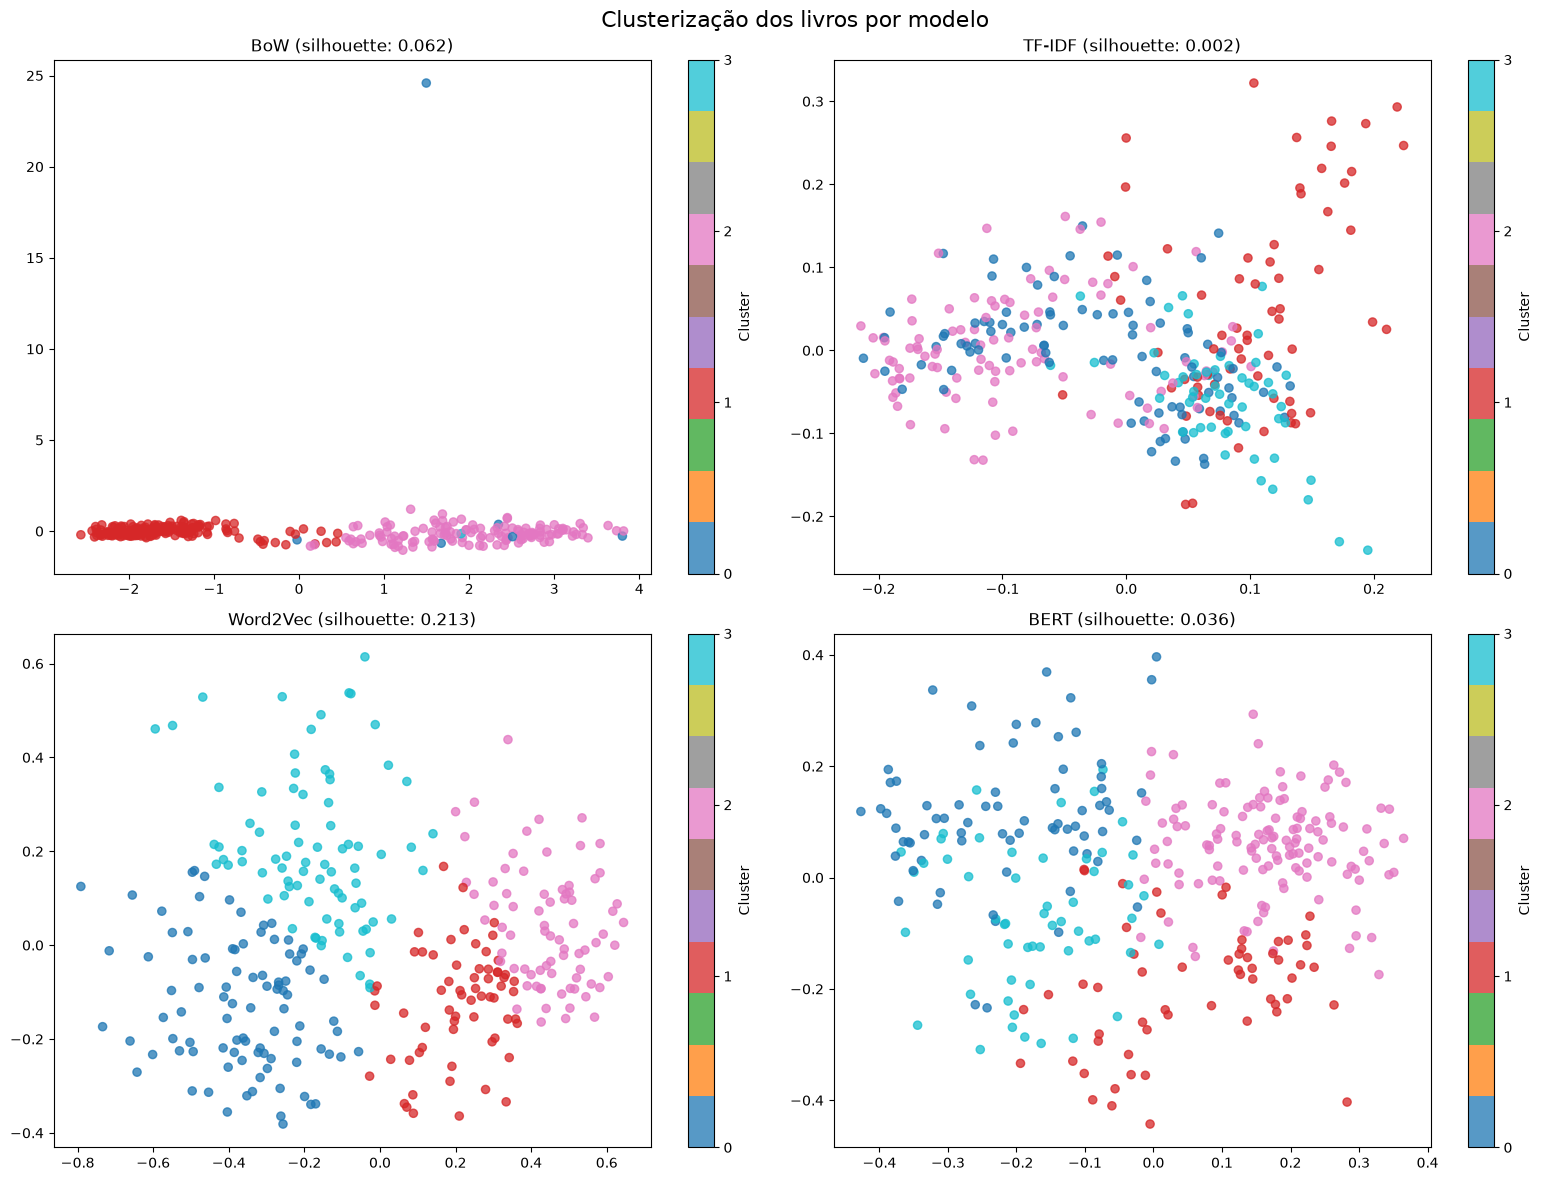

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

for ax, (nome, resultado) in zip(axes.flat, resultados_clusterizacao.items()):
    coordenadas = resultado['coordenadas_pca']
    pontos = ax.scatter(
        coordenadas[:, 0],
        coordenadas[:, 1],
        c=resultado['clusters'],
        cmap='tab10',
        vmin=0,
        vmax=N_CLUSTERS - 1,
        alpha=0.75,
        s=35
    )
    ax.set_title(f"{nome} (silhouette: {resultado['silhouette']:.3f})")
    fig.colorbar(pontos, ax=ax, ticks=range(N_CLUSTERS), label='Cluster')

fig.suptitle('Clusterização dos livros por modelo', fontsize=16)
fig.tight_layout()
plt.show()

### Busca e recomendação por modelo

busca e recomendação utilizando os clusters

In [22]:
TOP_N = 5
consulta_busca = 'science space exploration physics'


def representar_consulta(nome, consulta):
    if nome == 'BoW':
        return bow_vectorizer.transform([consulta])
    if nome == 'TF-IDF':
        return tfidf_vectorizer.transform([consulta])
    if nome == 'Word2Vec':
        tokens = consulta.lower().split()
        vetores = [model_w2v.wv[token] for token in tokens if token in model_w2v.wv]
        if not vetores:
            return np.zeros((1, model_w2v.vector_size))
        return np.mean(vetores, axis=0, keepdims=True)
    if nome == 'BERT':
        return bert_model.encode([consulta], show_progress_bar=False)
    raise ValueError(f'Modelo nao reconhecido: {nome}')


def buscar_e_recomendar(nome, consulta, top_n=TOP_N):
    matriz = representacoes[nome]
    clusters = resultados_clusterizacao[nome]['clusters']
    consulta_vetor = representar_consulta(nome, consulta)
    consulta_densa = (
        consulta_vetor.toarray()
        if hasattr(consulta_vetor, 'toarray')
        else np.asarray(consulta_vetor)
    )

    if not np.isfinite(consulta_densa).all() or np.linalg.norm(consulta_densa) == 0:
        print(f'{nome}: a consulta nao gerou uma representacao valida neste modelo.')
        return pd.DataFrame(columns=['book_id', 'title', 'subjects', 'cluster', 'similaridade'])

    centroides = np.vstack([
        np.asarray(matriz[clusters == cluster].mean(axis=0)).ravel()
        for cluster in range(N_CLUSTERS)
    ])
    cluster_consulta = int(np.linalg.norm(centroides - consulta_densa[0], axis=1).argmin())
    indices_cluster = np.flatnonzero(clusters == cluster_consulta)

    similaridades = cosine_similarity(
        consulta_vetor,
        matriz[indices_cluster]
    ).ravel()
    ordem = np.argsort(similaridades)[::-1][:top_n]
    indices_recomendados = indices_cluster[ordem]

    recomendacoes = df.iloc[indices_recomendados][['book_id', 'title', 'subjects']].copy()
    recomendacoes['cluster'] = cluster_consulta
    recomendacoes['similaridade'] = similaridades[ordem]
    return recomendacoes.reset_index(drop=True)


resultados_busca = {}
for nome in representacoes:
    print(f'\n=== {nome} | consulta: {consulta_busca!r} ===')
    recomendacoes = buscar_e_recomendar(nome, consulta_busca)
    resultados_busca[nome] = recomendacoes
    display(recomendacoes.rename(columns={
        'book_id': 'ID do livro',
        'title': 'Título',
        'subjects': 'Gêneros',
        'cluster': 'Cluster',
        'similaridade': 'Similaridade',
    }))


=== BoW | consulta: 'science space exploration physics' ===


,ID do livro,Título,Gêneros,Cluster,Similaridade
0,50290,Space Station 1,Science fiction | Love stories | Impostors and...,1,0.212598
1,76352,The world below,"Science fiction, English",1,0.163299
2,83,"From the Earth to the moon; and, round the moon",Science fiction | Space flight to the moon -- ...,1,0.077152
3,18857,A Journey to the Centre of the Earth,Science fiction | Adventure stories | Earth (P...,1,0.076472
4,36,The war of the worlds,Science fiction | War stories | Martians -- Fi...,1,0.072169



=== TF-IDF | consulta: 'science space exploration physics' ===


,ID do livro,Título,Gêneros,Cluster,Similaridade
0,19742,The Heather-Moon,Young women -- Fiction | Great Britain -- Fict...,0,0.064108
1,35,The Time Machine,Science fiction | Time travel -- Fiction | Dys...,0,0.062688
2,40284,The Sex Life of the Gods,Science fiction | Extraterrestrial beings -- F...,0,0.043597
3,23599,The Big Fix,Science fiction | Short stories | Telepathy --...,0,0.040876
4,76503,The man who mastered time,Science fiction | Time travel -- Fiction,0,0.040592



=== Word2Vec | consulta: 'science space exploration physics' ===


,ID do livro,Título,Gêneros,Cluster,Similaridade
0,57669,The problem of Cell 13,Detective and mystery stories | Boston (Mass.)...,3,0.969511
1,77099,"The magic ring, Vol. 3 (of 3)",German fiction -- Translations into English | ...,3,0.964635
2,9473,"The Knights of the Cross, or, Krzyzacy: Histor...",Teutonic Knights -- History -- Fiction | Polan...,3,0.959692
3,768,Wuthering Heights,Revenge -- Fiction | Psychological fiction | R...,3,0.959240
4,2610,Notre-Dame de Paris,Historical fiction | People with disabilities ...,3,0.959181



=== BERT | consulta: 'science space exploration physics' ===


,ID do livro,Título,Gêneros,Cluster,Similaridade
0,83,"From the Earth to the moon; and, round the moon",Science fiction | Space flight to the moon -- ...,3,0.334791
1,18857,A Journey to the Centre of the Earth,Science fiction | Adventure stories | Earth (P...,3,0.294658
2,50290,Space Station 1,Science fiction | Love stories | Impostors and...,3,0.275026
3,3526,"Five Weeks in a Balloon Or, Journeys and Disco...",Science fiction | Africa -- Fiction | Adventur...,3,0.241110
4,76352,The world below,"Science fiction, English",3,0.239494


### Classificação por modelo

lógica dos notebooks de classificação centralizadas nesta célula. A acurácia, o F1 macro, o relatório por gênero e a matriz de confusão são apresentados para cada modelo.

In [ ]:
import re
import unicodedata

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)

SEMENTE_CLASSIFICACAO = 42
TEST_SIZE_CLASSIFICACAO = 0.25
MIN_AMOSTRAS_POR_GENERO = 1

def normalizar_para_regra(texto):
    texto = "" if pd.isna(texto) else str(texto).lower()
    texto = unicodedata.normalize("NFKD", texto)
    return "".join(c for c in texto if not unicodedata.combining(c))


def identificar_genero(subjects):
    s = normalizar_para_regra(subjects)

    regras = [
        (
            "Ficção científica/fantasia",
            [
                r"science fiction",
                r"fantasy fiction",
                r"fantasy stories",
                r"utopias?",
                r"dystopias?",
            ],
        ),
        (
            "Mistério/policial",
            [
                r"detective and mystery stories",
                r"detective stories",
                r"mystery fiction",
                r"crime fiction",
                r"police stories",
                r"suspense fiction",
            ],
        ),
        (
            "Terror/gótico",
            [
                r"horror fiction",
                r"horror tales?",
                r"ghost stories",
                r"gothic fiction",
                r"supernatural fiction",
                r"vampire fiction",
                r"paranormal fiction",
            ],
        ),
        (
            "Romance",
            [
                r"love stories",
                r"romance fiction",
                r"romantic fiction",
                r"courtship.{0,30}fiction",
            ],
        ),
        (
            "Guerra",
            [
                r"war stories",
                r"war fiction",
                r"military fiction",
                r"world war.{0,30}fiction",
            ],
        ),
        (
            "Aventura",
            [
                r"adventure stories",
                r"adventure fiction",
                r"sea stories",
                r"pirates.{0,30}fiction",
            ],
        ),
        (
            "Ficção histórica",
            [
                r"historical fiction",
                r"historical stories",
            ],
        ),
        (
            "Faroeste",
            [
                r"western stories",
                r"cowboy stories",
                r"western fiction",
            ],
        ),

        (
            "Romance de formação",
            [
                r"\bbildungsromans?\b",
            ],
        ),
        (
            "Ficção doméstica/familiar",
            [
                r"\bdomestic fiction\b",
            ],
        ),
        (
            "Ficção psicológica",
            [
                r"\bpsychological fiction\b",
            ],
        ),
        (
            "Humor",
            [
                r"\bhumorous stories?\b",
            ],
        ),
        (
            "Ficção didática",
            [
                r"\bdidactic fiction\b",
            ],
        ),
        (
            "Ficção autobiográfica",
            [
                r"\bautobiographical fiction\b",
            ],
        ),
        (
            "Ficção epistolar",
            [
                r"\bepistolary fiction\b",
            ],
        ),
        (
            "Ficção política",
            [
                r"\bpolitical fiction\b",
            ],
        ),
        (
            "Romance literário",
            [
                r"\bromances\b",
            ],
        ),
        (
            "Literatura infantil/juvenil",
            [
                r"\bjuvenile fiction\b",
                r"\bchildren['’]s stories\b",
            ],
        ),
        (
            "Poesia",
            [
                r"\bpoetry\b",
                r"\bpoems?\b",
                r"\bsonnets?\b",
            ],
        ),
    ]

    for genero, padroes in regras:
        if any(re.search(padrao, s) for padrao in padroes):
            return genero

    return np.nan



df_classificacao = pd.read_csv('gutenberg_books.csv', dtype={'book_id': str})

if 'text_final' in df_classificacao.columns:
    coluna_texto_classificacao = 'text_final'
elif 'summary' in df_classificacao.columns:
    coluna_texto_classificacao = 'summary'
elif 'trecho_1_clean' in df_classificacao.columns:
    coluna_texto_classificacao = 'trecho_1_clean'
else:
    raise ValueError("Não encontrado 'text_final', 'summary' nem 'trecho_1_clean' no CSV.")

df_classificacao['texto_classificacao'] = (
    df_classificacao[coluna_texto_classificacao].fillna('').astype(str).str.strip()
)

if 'genero' in df_classificacao.columns and df_classificacao['genero'].notna().any():
    df_classificacao['genero'] = df_classificacao['genero'].astype(str).str.strip()
    df_classificacao.loc[
        df_classificacao['genero'].str.lower().isin(['', 'nan', 'none', 'null']),
        'genero'
    ] = np.nan
else:
    if 'subjects' not in df_classificacao.columns:
        raise ValueError(
            "O CSV precisa ter a coluna 'genero' ou os metadados 'subjects' para classificar."
        )
    df_classificacao['genero'] = df_classificacao['subjects'].apply(identificar_genero)

df_classificacao = df_classificacao[
    (df_classificacao['texto_classificacao'] != '') & df_classificacao['genero'].notna()
].copy()
contagem_generos = df_classificacao['genero'].value_counts()
generos_validos = contagem_generos[
    contagem_generos >= MIN_AMOSTRAS_POR_GENERO
].index
df_classificacao = df_classificacao[
    df_classificacao['genero'].isin(generos_validos)
].reset_index(drop=True)

if df_classificacao['genero'].nunique() < 2:
    raise ValueError(
        'Foram encontrados menos de dois gêneros. Verifique os rótulos e a coluna subjects.'
    )

indices_classificacao = np.arange(len(df_classificacao))
rotulos_classificacao = df_classificacao['genero'].to_numpy()
indices_treino, indices_teste = train_test_split(
    indices_classificacao,
    test_size=TEST_SIZE_CLASSIFICACAO,
    random_state=SEMENTE_CLASSIFICACAO,
    stratify=rotulos_classificacao,
)
texto_treino_classificacao = df_classificacao.iloc[indices_treino][
    'texto_classificacao'
].tolist()
texto_teste_classificacao = df_classificacao.iloc[indices_teste][
    'texto_classificacao'
].tolist()
y_treino_classificacao = df_classificacao.iloc[indices_treino]['genero'].to_numpy()
y_teste_classificacao = df_classificacao.iloc[indices_teste]['genero'].to_numpy()

print(f'Coluna textual usada: {coluna_texto_classificacao}')
print(f'Livros classificados: {len(df_classificacao)}')
print(f'Treino: {len(indices_treino)} | Teste: {len(indices_teste)}')
print('Distribuição dos gêneros:')
display(df_classificacao['genero'].value_counts().rename_axis('Gênero').to_frame('Livros'))

representador_bow_classificacao = CountVectorizer()
X_treino_bow = representador_bow_classificacao.fit_transform(texto_treino_classificacao)
X_teste_bow = representador_bow_classificacao.transform(texto_teste_classificacao)

representador_tfidf_classificacao = TfidfVectorizer()
X_treino_tfidf = representador_tfidf_classificacao.fit_transform(texto_treino_classificacao)
X_teste_tfidf = representador_tfidf_classificacao.transform(texto_teste_classificacao)

tokens_treino_classificacao = [texto.lower().split() for texto in texto_treino_classificacao]
tokens_teste_classificacao = [texto.lower().split() for texto in texto_teste_classificacao]
modelo_w2v_classificacao = Word2Vec(
    sentences=tokens_treino_classificacao,
    vector_size=100,
    window=5,
    min_count=2,
    workers=1,
    sg=1,
    epochs=20,
)


def embedding_livro_classificacao(tokens, modelo):
    vetores = [modelo.wv[token] for token in tokens if token in modelo.wv]
    if not vetores:
        return np.zeros(modelo.vector_size)
    return np.mean(vetores, axis=0)


X_treino_w2v = np.array([
    embedding_livro_classificacao(tokens, modelo_w2v_classificacao)
    for tokens in tokens_treino_classificacao
])
X_teste_w2v = np.array([
    embedding_livro_classificacao(tokens, modelo_w2v_classificacao)
    for tokens in tokens_teste_classificacao
])

X_treino_bert = bert_model.encode(
    texto_treino_classificacao,
    show_progress_bar=True,
    convert_to_numpy=True,
)
X_teste_bert = bert_model.encode(
    texto_teste_classificacao,
    show_progress_bar=True,
    convert_to_numpy=True,
)

representacoes_classificacao = {
    'BoW': (X_treino_bow, X_teste_bow),
    'TF-IDF': (X_treino_tfidf, X_teste_tfidf),
    'Word2Vec': (X_treino_w2v, X_teste_w2v),
    'BERT': (X_treino_bert, X_teste_bert),
}

classificadores_genero = {}
predicoes_classificacao = {}
metricas_classificacao = []

for nome, (X_treino_modelo, X_teste_modelo) in representacoes_classificacao.items():
    classificador = LogisticRegression(
        max_iter=2000,
        class_weight='balanced',
        random_state=SEMENTE_CLASSIFICACAO,
    )
    classificador.fit(X_treino_modelo, y_treino_classificacao)
    predicoes = classificador.predict(X_teste_modelo)

    classificadores_genero[nome] = classificador
    predicoes_classificacao[nome] = predicoes
    metricas_classificacao.append({
        'Modelo': nome,
        'Acurácia': accuracy_score(y_teste_classificacao, predicoes),
        'F1 macro': f1_score(
            y_teste_classificacao,
            predicoes,
            average='macro',
            zero_division=0,
        ),
    })

    print(f'\n=== {nome} ===')
    print(classification_report(y_teste_classificacao, predicoes, zero_division=0))
    rotulos = sorted(set(y_teste_classificacao) | set(predicoes))
    matriz_confusao = confusion_matrix(
        y_teste_classificacao,
        predicoes,
        labels=rotulos,
    )
    display(pd.DataFrame(
        matriz_confusao,
        index=rotulos,
        columns=rotulos,
    ).rename_axis('Real \\ Previsto'))

resumo_classificacao = pd.DataFrame(metricas_classificacao).sort_values(
    'F1 macro', ascending=False
).reset_index(drop=True)
display(resumo_classificacao)


Coluna textual usada: text_final
Livros classificados: 218
Treino: 163 | Teste: 55
Distribuição dos gêneros:


,Livros
Gênero,
Mistério/policial,48
Romance,35
Ficção científica/fantasia,31
Aventura,17
Terror/gótico,14
Romance de formação,11
Guerra,8
Romance literário,8
Literatura infantil/juvenil,7


Batches: 100%|██████████| 2/2 [00:02<00:00,  1.19s/it]



=== BoW ===
                             precision    recall  f1-score   support

                   Aventura       0.50      0.75      0.60         4
                   Faroeste       0.00      0.00      0.00         1
 Ficção científica/fantasia       0.62      0.62      0.62         8
            Ficção didática       0.00      0.00      0.00         1
  Ficção doméstica/familiar       0.00      0.00      0.00         1
           Ficção epistolar       0.00      0.00      0.00         1
           Ficção histórica       0.00      0.00      0.00         1
            Ficção política       0.00      0.00      0.00         1
         Ficção psicológica       0.00      0.00      0.00         1
                     Guerra       0.00      0.00      0.00         2
                      Humor       0.00      0.00      0.00         1
Literatura infantil/juvenil       0.00      0.00      0.00         2
          Mistério/policial       0.59      0.83      0.69        12
                    

,Aventura,Faroeste,Ficção científica/fantasia,Ficção didática,Ficção doméstica/familiar,Ficção epistolar,Ficção histórica,Ficção política,Ficção psicológica,Guerra,Humor,Literatura infantil/juvenil,Mistério/policial,Poesia,Romance,Romance de formação,Romance literário,Terror/gótico
Real \ Previsto,,,,,,,,,,,,,,,,,,
Aventura,3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
Faroeste,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
Ficção científica/fantasia,1,0,5,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1
Ficção didática,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
Ficção doméstica/familiar,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
Ficção epistolar,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Ficção histórica,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
Ficção política,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Ficção psicológica,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0


...


=== Word2Vec ===
                             precision    recall  f1-score   support

                   Aventura       0.00      0.00      0.00         4
                   Faroeste       0.00      0.00      0.00         1
 Ficção científica/fantasia       0.00      0.00      0.00         8
            Ficção didática       0.00      0.00      0.00         1
  Ficção doméstica/familiar       0.00      0.00      0.00         1
           Ficção epistolar       0.00      0.00      0.00         1
           Ficção histórica       0.00      0.00      0.00         1
            Ficção política       0.00      0.00      0.00         1
         Ficção psicológica       0.00      0.00      0.00         1
                     Guerra       0.00      0.00      0.00         2
                      Humor       0.00      0.00      0.00         1
Literatura infantil/juvenil       0.07      0.50      0.12         2
          Mistério/policial       0.00      0.00      0.00        12
               

,Aventura,Faroeste,Ficção científica/fantasia,Ficção didática,Ficção doméstica/familiar,Ficção epistolar,Ficção histórica,Ficção política,Ficção psicológica,Guerra,Humor,Literatura infantil/juvenil,Mistério/policial,Poesia,Romance,Romance de formação,Romance literário,Terror/gótico
Real \ Previsto,,,,,,,,,,,,,,,,,,
Aventura,0,0,0,0,0,0,0,0,0,0,0,2,0,0,0,0,1,1
Faroeste,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
Ficção científica/fantasia,0,1,0,0,0,0,0,0,0,0,0,2,0,0,0,1,0,4
Ficção didática,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
Ficção doméstica/familiar,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
Ficção epistolar,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
Ficção histórica,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
Ficção política,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
Ficção psicológica,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0



=== BERT ===
                             precision    recall  f1-score   support

                   Aventura       0.50      0.50      0.50         4
                   Faroeste       0.00      0.00      0.00         1
 Ficção científica/fantasia       0.43      0.38      0.40         8
            Ficção didática       0.00      0.00      0.00         1
  Ficção doméstica/familiar       0.00      0.00      0.00         1
           Ficção epistolar       0.00      0.00      0.00         1
           Ficção histórica       0.00      0.00      0.00         1
            Ficção política       0.00      0.00      0.00         1
         Ficção psicológica       0.00      0.00      0.00         1
                     Guerra       0.00      0.00      0.00         2
                      Humor       0.00      0.00      0.00         1
Literatura infantil/juvenil       0.50      1.00      0.67         2
          Mistério/policial       0.64      0.58      0.61        12
                   

,Aventura,Faroeste,Ficção científica/fantasia,Ficção didática,Ficção doméstica/familiar,Ficção epistolar,Ficção histórica,Ficção política,Ficção psicológica,Guerra,Humor,Literatura infantil/juvenil,Mistério/policial,Poesia,Romance,Romance de formação,Romance literário,Terror/gótico
Real \ Previsto,,,,,,,,,,,,,,,,,,
Aventura,2,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
Faroeste,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Ficção científica/fantasia,1,0,3,0,0,0,0,0,0,0,0,0,1,0,0,0,1,2
Ficção didática,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
Ficção doméstica/familiar,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
Ficção epistolar,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Ficção histórica,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
Ficção política,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
Ficção psicológica,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0


,Modelo,Acurácia,F1 macro
0,TF-IDF,0.618182,0.405346
1,BERT,0.472727,0.322394
2,BoW,0.581818,0.300655
3,Word2Vec,0.036364,0.012092


### Visualizações dos resultados da classificação

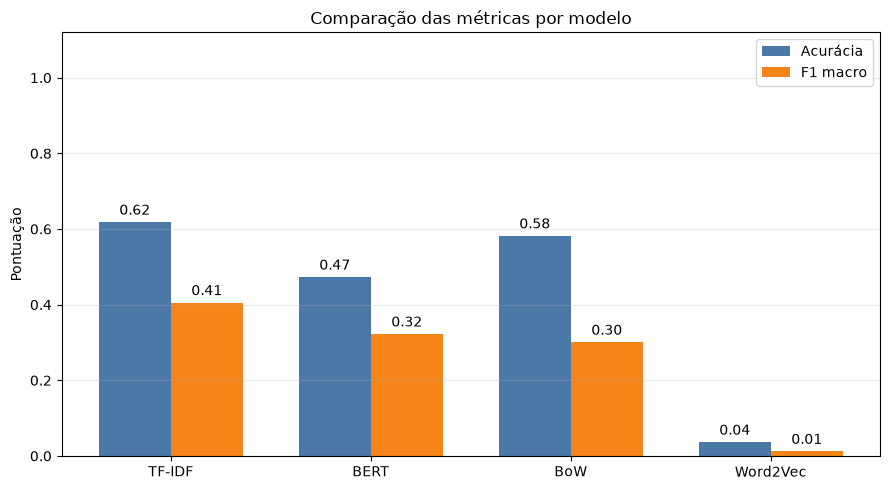

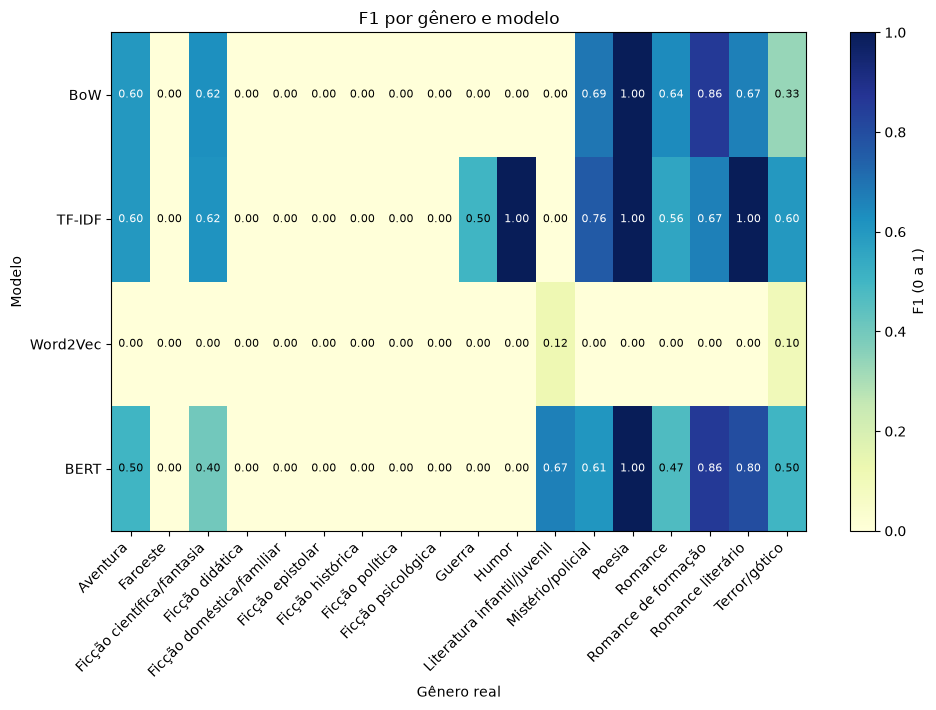

In [24]:
fig, ax = plt.subplots(figsize=(9, 5))
posicoes = np.arange(len(resumo_classificacao))
largura = 0.36

barras_acuracia = ax.bar(
    posicoes - largura / 2,
    resumo_classificacao['Acurácia'],
    largura,
    label='Acurácia',
    color='#4C78A8',
)
barras_f1 = ax.bar(
    posicoes + largura / 2,
    resumo_classificacao['F1 macro'],
    largura,
    label='F1 macro',
    color='#F58518',
)

ax.bar_label(barras_acuracia, fmt='%.2f', padding=3)
ax.bar_label(barras_f1, fmt='%.2f', padding=3)
ax.set_xticks(posicoes, resumo_classificacao['Modelo'])
ax.set_ylim(0, 1.12)
ax.set_ylabel('Pontuação')
ax.set_title('Comparação das métricas por modelo')
ax.legend()
ax.grid(axis='y', alpha=0.25)
fig.tight_layout()
plt.show()

generos_avaliados = sorted(set(y_teste_classificacao))
modelos_avaliados = list(predicoes_classificacao)
relatorios_por_modelo = {
    nome: classification_report(
        y_teste_classificacao,
        predicoes_classificacao[nome],
        labels=generos_avaliados,
        output_dict=True,
        zero_division=0,
    )
    for nome in modelos_avaliados
}
f1_por_genero = np.array([
    [relatorios_por_modelo[nome][genero]['f1-score'] for genero in generos_avaliados]
    for nome in modelos_avaliados
])

fig, ax = plt.subplots(figsize=(10, max(6, len(generos_avaliados) * 0.4)))
imagem = ax.imshow(f1_por_genero, cmap='YlGnBu', vmin=0, vmax=1, aspect='auto')
ax.set_xticks(np.arange(len(generos_avaliados)), generos_avaliados, rotation=45, ha='right')
ax.set_yticks(np.arange(len(modelos_avaliados)), modelos_avaliados)
ax.set_title('F1 por gênero e modelo')
ax.set_xlabel('Gênero real')
ax.set_ylabel('Modelo')

for linha in range(len(modelos_avaliados)):
    for coluna in range(len(generos_avaliados)):
        ax.text(
            coluna,
            linha,
            f'{f1_por_genero[linha, coluna]:.2f}',
            ha='center',
            va='center',
            color='white' if f1_por_genero[linha, coluna] >= 0.55 else 'black',
            fontsize=8,
        )

fig.colorbar(imagem, ax=ax, label='F1 (0 a 1)')
fig.tight_layout()
plt.show()